# 01. Exploratory Data Analysis & Data Cleaning
Exploring the U.S. Housing Time-Series dataset (`HouseTS.csv`, 2012–2023) and enriching it with geographic coordinates from `uscities.csv`.

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import colorsys

# Show all columns in the DataFrame
pd.set_option('display.max_columns', None)

In [19]:
# Load the raw datasets
df_houses = pd.read_csv('../data/raw/HouseTS.csv')
df_cities = pd.read_csv('../data/raw/uscities.csv')

print(f"HouseTS shape: {df_houses.shape}")
print(f"US Cities shape: {df_cities.shape}")

HouseTS shape: (884092, 39)
US Cities shape: (28338, 17)


In [20]:
df_houses.head()

,date,median_sale_price,median_list_price,median_ppsf,median_list_ppsf,homes_sold,pending_sales,new_listings,inventory,median_dom,avg_sale_to_list,sold_above_list,off_market_in_two_weeks,city,zipcode,year,bank,bus,hospital,mall,park,restaurant,school,station,supermarket,Total Population,Median Age,Per Capita Income,Total Families Below Poverty,Total Housing Units,Median Rent,Median Home Value,Total Labor Force,Unemployed Population,Total School Age Population,Total School Enrollment,Median Commute Time,price,city_full
0,2012-03-31,46550.0,217450.0,31.813674,110.183666,14.0,23.0,44.0,64.0,59.5,0.943662,0.142857,0.043478,ATL,30002,2012,12.0,2.0,4.0,1.0,60.0,45.0,57.0,4.0,7.0,5811.0,36.3,33052.0,5811.0,2677.0,710.0,279500.0,3171.0,460.0,5408.0,5408.0,2492.0,200773.999557,Atlanta-Sandy Springs-Alpharetta
1,2012-04-30,61870.0,245000.0,40.723982,130.528256,22.0,29.0,56.0,69.0,89.5,0.946642,0.090909,0.034483,ATL,30002,2012,12.0,2.0,4.0,1.0,60.0,45.0,57.0,4.0,7.0,5811.0,36.3,33052.0,5811.0,2677.0,710.0,279500.0,3171.0,460.0,5408.0,5408.0,2492.0,202421.064584,Atlanta-Sandy Springs-Alpharetta
2,2012-05-31,125500.0,217450.0,63.913043,119.919216,24.0,40.0,63.0,60.0,144.5,0.955624,0.208333,0.100000,ATL,30002,2012,12.0,2.0,4.0,1.0,60.0,45.0,57.0,4.0,7.0,5811.0,36.3,33052.0,5811.0,2677.0,710.0,279500.0,3171.0,460.0,5408.0,5408.0,2492.0,202681.309539,Atlanta-Sandy Springs-Alpharetta
3,2012-06-30,153000.0,189900.0,81.598080,105.617353,34.0,46.0,50.0,57.0,126.0,0.970608,0.176471,0.108696,ATL,30002,2012,12.0,2.0,4.0,1.0,60.0,45.0,57.0,4.0,7.0,5811.0,36.3,33052.0,5811.0,2677.0,710.0,279500.0,3171.0,460.0,5408.0,5408.0,2492.0,202998.603897,Atlanta-Sandy Springs-Alpharetta
4,2012-07-31,165500.0,154000.0,81.598080,83.921175,39.0,49.0,42.0,50.0,80.0,0.982105,0.256410,0.102041,ATL,30002,2012,12.0,2.0,3.0,1.0,60.0,45.0,57.0,4.0,6.0,5811.0,36.3,33052.0,5811.0,2677.0,710.0,279500.0,3171.0,460.0,5408.0,5408.0,2492.0,203781.903446,Atlanta-Sandy Springs-Alpharetta


In [21]:
df_cities.head()

,city,city_ascii,state_id,state_name,county_fips,county_name,lat,lng,population,density,source,military,incorporated,timezone,ranking,zips,id
0,New York,New York,NY,New York,36061,New York,40.6943,-73.9249,18713220,10715,polygon,False,True,America/New_York,1,11229 11226 11225 11224 11222 11221 11220 1138...,1840034016
1,Los Angeles,Los Angeles,CA,California,6037,Los Angeles,34.1139,-118.4068,12750807,3276,polygon,False,True,America/Los_Angeles,1,90291 90293 90292 91316 91311 90037 90031 9000...,1840020491
2,Chicago,Chicago,IL,Illinois,17031,Cook,41.8373,-87.6862,8604203,4574,polygon,False,True,America/Chicago,1,60018 60649 60641 60640 60643 60642 60645 6064...,1840000494
3,Miami,Miami,FL,Florida,12086,Miami-Dade,25.7839,-80.2102,6445545,5019,polygon,False,True,America/New_York,1,33129 33125 33126 33127 33128 33149 33144 3314...,1840015149
4,Dallas,Dallas,TX,Texas,48113,Dallas,32.7936,-96.7662,5743938,1526,polygon,False,True,America/Chicago,1,75287 75098 75233 75254 75251 75252 75253 7503...,1840019440


In [22]:
# Summary statistics for numerical features
df_houses.describe().T

,count,mean,std,min,25%,50%,75%,max
median_sale_price,884092.0,394102.625778,3.815481e+05,0.000000,185000.000000,302500.000000,480000.000000,2.050000e+07
median_list_price,884092.0,422984.881392,1.899201e+06,0.000000,199000.000000,320000.000000,499900.000000,1.000000e+09
median_ppsf,884092.0,223.068328,6.967242e+02,0.000000,110.639667,166.093929,260.626280,3.667000e+05
median_list_ppsf,884092.0,231.169836,2.901202e+02,0.000000,116.818175,173.142587,270.181473,1.430154e+05
homes_sold,884092.0,76.722786,7.669833e+01,0.000000,19.000000,55.000000,111.000000,9.550000e+02
pending_sales,884092.0,81.471457,8.532762e+01,0.000000,17.000000,57.000000,119.000000,1.374000e+03
new_listings,884092.0,92.910352,9.269585e+01,0.000000,24.000000,67.000000,133.000000,1.112000e+03
inventory,884092.0,77.300772,8.904177e+01,0.000000,20.000000,50.000000,103.000000,1.941000e+03
median_dom,884092.0,61.289875,8.222050e+01,0.000000,26.000000,45.000000,74.000000,7.777000e+03
avg_sale_to_list,884092.0,0.978253,6.354957e-02,0.000000,0.965158,0.982062,0.998206,1.906250e+00


In [23]:
# Convert date column to datetime and check the range
df_houses['date'] = pd.to_datetime(df_houses['date'])
print(f"Date range: {df_houses['date'].min().date()} to {df_houses['date'].max().date()}")
print(f"Total unique months: {df_houses['date'].nunique()}")
print("\nRecords per year:")
print(df_houses['date'].dt.year.value_counts().sort_index())

Date range: 2012-03-31 to 2023-12-31
Total unique months: 142

Records per year:
date
2012    62260
2013    74712
2014    74712
2015    74712
2016    74712
2017    74712
2018    74712
2019    74712
2020    74712
2021    74712
2022    74712
2023    74712
Name: count, dtype: int64


In [24]:
# Check missing values per column
missing = df_houses.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if len(missing > 0):
    print(f"Columns with missing values:\n{missing}")
else:
    print("No missing values found!")

No missing values found!


In [25]:
# Check how many zeros are in key price columns
print("Zeros in median_sale_price:", (df_houses['median_sale_price'] == 0).sum())
print("Zeros in price:", (df_houses['price'] == 0).sum())
print("Zeros in median_list_price:", (df_houses['median_list_price'] == 0).sum())

Zeros in median_sale_price: 2272
Zeros in price: 0
Zeros in median_list_price: 2698


## 1. Geographic Mapping (`lat` / `lng` Enrichment)
Instead of high-cardinality one-hot encoding for cities, we map each metropolitan area (`city_full`) to its primary city's latitude and longitude from `uscities.csv`.
- Note: `DC_Metro` does not match directly and is explicitly mapped to `Washington`.

In [26]:
# Keep the most populous city per name in uscities to ensure a strict 1-to-1 merge
cities_coords = (
    df_cities.sort_values('population', ascending=False)
    .drop_duplicates('city')[['city', 'lat', 'lng']]
    .rename(columns={'city': 'primary_city'})
)

# Extract primary city from 'city_full' and fix the DC_Metro naming mismatch
df_houses['primary_city'] = df_houses['city_full'].apply(
    lambda x: 'Washington' if x == 'DC_Metro' else x.split('-')[0].strip()
)

# Merge lat and lng into df_houses
df_houses = df_houses.merge(cities_coords, on='primary_city', how='left')
df_houses = df_houses.drop(columns=['primary_city'])

missing_coords = df_houses[df_houses['lat'].isnull()]['city_full'].unique()
if len(missing_coords) > 0:
    print("Still missing lat/lng for:", missing_coords)
else:
    print(f"All {df_houses['city_full'].nunique()} metropolitan areas successfully matched with lat/lng!")
print("Updated shape:", df_houses.shape)

All 30 metropolitan areas successfully matched with lat/lng!
Updated shape: (884092, 41)


## 2. Duplicate Records Removal
We check both exact row duplicates and duplicated records across different timestamps (`date`, `year`), which represent forward-filled stale monthly snapshots.

In [27]:
cols_without_time = df_houses.columns.difference(['date', 'year'])

print("Full duplicates:", df_houses.duplicated().sum())
print("Duplicates excluding date/year:", df_houses.duplicated(subset=cols_without_time).sum())

# Drop stale duplicates
df_houses = df_houses.drop_duplicates(subset=cols_without_time, keep=False).copy()
print("Shape after dropping duplicates:", df_houses.shape)

Full duplicates: 0
Duplicates excluding date/year: 7390
Shape after dropping duplicates: (874254, 41)


## 3. Outlier Detection & Removal (`median_list_price`)
`median_list_price` has a maximum value of $1,000,000,000 ($1B). By inspecting the violin distribution and top 1% value frequencies, we observe an artificial cluster of 38 repeated listings at `$19,990,000` and extreme typos above it (`$50.4M`, `$999.9M`). We filter out records above `$19,000,000`.

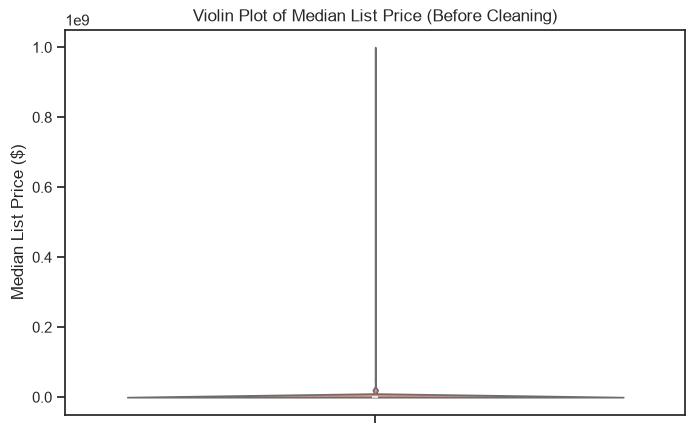

Top extreme values in median_list_price (value counts):
median_list_price
999999999.0     3
50449949.5      3
50359500.0      2
50334950.0      1
27800000.0      1
19990000.0     38
18500000.0      3
15849000.0      1
15624500.0      3
15500000.0      1
Name: count, dtype: int64


In [28]:
# Violin plot BEFORE removing extreme outliers
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(y=df_houses['median_list_price'], ax=ax, color='salmon', inner='box')
ax.set_title("Violin Plot of Median List Price (Before Cleaning)")
ax.set_ylabel("Median List Price ($)")
plt.show()

# Inspect top 1% largest values frequency
top_1_percent = df_houses.nlargest(int(0.01 * len(df_houses)), 'median_list_price')
print("Top extreme values in median_list_price (value counts):")
print(top_1_percent['median_list_price'].value_counts().sort_index(ascending=False).head(10))

Shape after removing outliers: (874206, 41)


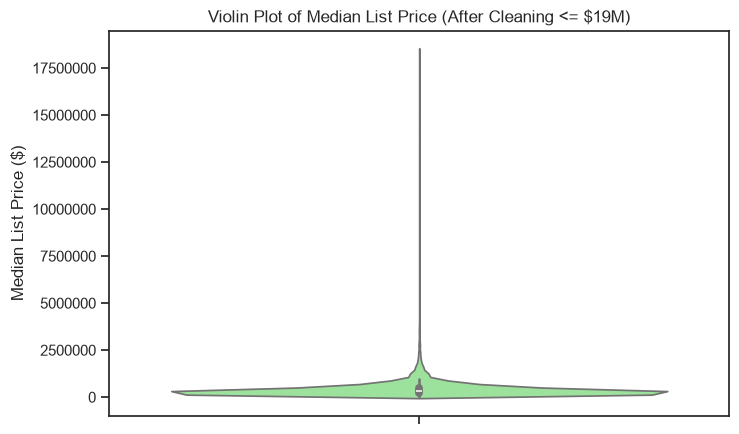

In [29]:
# Remove extreme outliers above $19M
df_houses = df_houses[df_houses['median_list_price'] <= 19_000_000].copy()
print("Shape after removing outliers:", df_houses.shape)

# Violin plot AFTER removing extreme outliers
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(y=df_houses['median_list_price'], ax=ax, color='lightgreen', inner='box')
ax.set_title("Violin Plot of Median List Price (After Cleaning <= $19M)")
ax.set_ylabel("Median List Price ($)")
ax.ticklabel_format(axis='y', style='plain')
plt.show()

## 4. Housing Prices Exploration Across U.S. Cities
Visualizing the price distribution across all 30 metropolitan cities ordered by median housing price, followed by the overall target distribution.

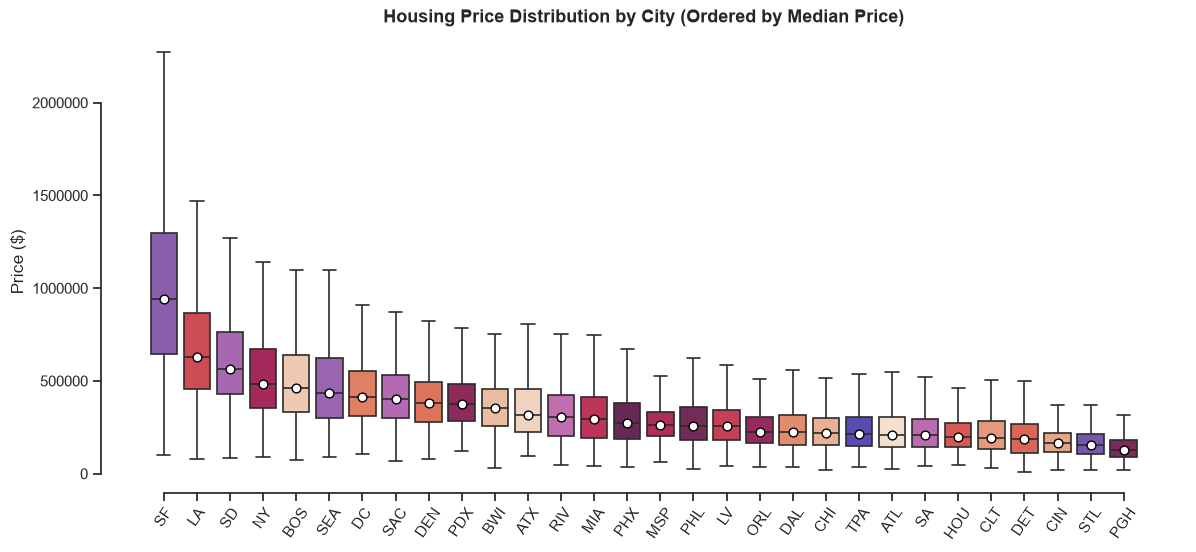

In [30]:
# Boxplot of house prices for the 30 cities, ordered by median price
top_cities = df_houses["city"].value_counts().head(30).index.tolist()
df_city = df_houses[df_houses["city"].isin(top_cities)]

city_order = (
    df_city.groupby("city")["price"]
    .median()
    .sort_values(ascending=False)
    .index
)

base = sns.color_palette("rocket_r", len(city_order))

def lighten(color, amt=0.4):
    h, l, s = colorsys.rgb_to_hls(*color)
    return colorsys.hls_to_rgb(h, min(1, l + amt * (1 - l)), s)

palette = [
    lighten(c, 0.45) if i >= len(base) - 8 else c
    for i, c in enumerate(base)
]

sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    x="city", y="price", hue="city", data=df_city,
    order=city_order, palette=palette, legend=False,
    showfliers=False, linewidth=1.2, ax=ax
)

medians = df_city.groupby("city")["price"].median().loc[city_order]
for tick, median in enumerate(medians):
    ax.scatter(tick, median, color="white", edgecolor="black", zorder=5, s=40)

ax.set_title("Housing Price Distribution by City (Ordered by Median Price)", fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Price ($)")
ax.tick_params(axis="x", rotation=55)
sns.despine(trim=True)
ax.grid(False)
ax.ticklabel_format(axis="y", style="plain")
plt.show()

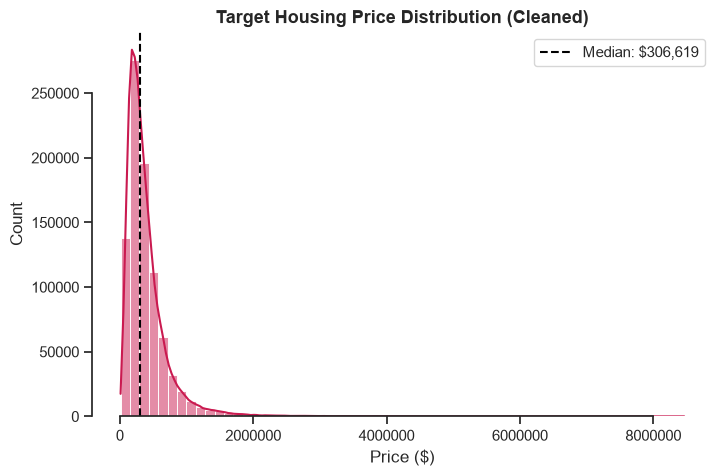

In [31]:
# Distribution of house prices across the cleaned dataset
sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    df_houses["price"].dropna(),
    bins=60, kde=True,
    color=sns.color_palette("rocket_r", 1)[0], ax=ax
)

median_price = df_houses["price"].median()
ax.axvline(median_price, ls="--", lw=1.5, color="black", label=f"Median: ${median_price:,.0f}")

ax.set_title("Target Housing Price Distribution (Cleaned)", fontsize=13, fontweight="bold")
ax.set_xlabel("Price ($)")
ax.set_ylabel("Count")
ax.legend()
sns.despine(trim=True)
ax.grid(False)
ax.ticklabel_format(axis="x", style="plain")
plt.show()

In [32]:
# Rows still suspicious after the $19M cut: list price > 10x market price
price_ratio = df_houses['median_list_price'] / df_houses['price']
suspicious = df_houses[price_ratio > 10]
print("Suspicious rows:", len(suspicious))
print(suspicious[['date', 'city_full', 'zipcode', 'median_list_price', 'price', 'homes_sold']]
      .sort_values('median_list_price', ascending=False).head(15))
print(suspicious['homes_sold'].describe())

Suspicious rows: 140
             date                       city_full  zipcode  median_list_price  \
834358 2021-03-31  San Francisco-Oakland-Berkeley    94946         18500000.0   
581086 2014-01-31     New York-Newark-Jersey City    11964         13995000.0   
814445 2018-06-30  San Francisco-Oakland-Berkeley    94060         13100000.0   
814444 2018-05-31  San Francisco-Oakland-Berkeley    94060         13100000.0   
783108 2022-03-31  San Diego-Chula Vista-Carlsbad    92059         12500000.0   
560593 2022-02-28     New York-Newark-Jersey City    11509         11600000.0   
766310 2018-09-30     Sacramento-Roseville-Folsom    95668         10692000.0   
766311 2018-10-31     Sacramento-Roseville-Folsom    95668         10692000.0   
766306 2018-05-31     Sacramento-Roseville-Folsom    95668         10692000.0   
766307 2018-06-30     Sacramento-Roseville-Folsom    95668         10692000.0   
766308 2018-07-31     Sacramento-Roseville-Folsom    95668         10692000.0   
766309 

In [33]:
demo_cols = ['Total Population', 'Median Age', 'Per Capita Income',
             'Median Rent', 'Median Home Value', 'Total Housing Units']
print((df_houses[demo_cols] == 0).sum())
print("Zipcodes affected:", df_houses.loc[(df_houses[demo_cols] == 0).any(axis=1), 'zipcode'].nunique())

Total Population       66928
Median Age             66753
Per Capita Income      66753
Median Rent            66753
Median Home Value      66753
Total Housing Units    66868
dtype: int64
Zipcodes affected: 479
